# Simple Linear Regression

**Goal:** predict a house's price from **one** input, its size.

**The idea:** draw the straight line that fits the data best:

$$\hat{y} = b + w \cdot x$$

- $w$ (slope) = how much the price changes when size goes up by 1 m²
- $b$ (intercept) = the predicted price when size is 0
- "Best" line = the one that makes the **sum of squared errors** smallest (least squares)

## 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the data

Each row is one house. `price_thousands` is what we want to predict.

In [ ]:
df = pd.read_csv("house_prices.csv")
df.head()

,size_m2,bedrooms,age_years,price_thousands
0,85.8,2,29,110.30
1,178.0,2,28,212.87
2,143.5,1,13,200.79
3,124.1,3,17,180.44
4,121.0,3,26,188.97


In [ ]:
df.describe()

,size_m2,bedrooms,age_years,price_thousands
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,150.983420,2.564400,25.220400,206.544468
std,57.210401,1.136711,14.665144,77.790509
min,50.100000,1.000000,0.000000,27.180000
25%,102.300000,2.000000,13.000000,140.220000
50%,151.300000,3.000000,25.000000,206.330000
75%,199.800000,3.000000,38.000000,271.357500
max,250.000000,6.000000,50.000000,381.400000


## 3. Look at the data first

Before modelling, check that the relationship looks roughly like a straight line.

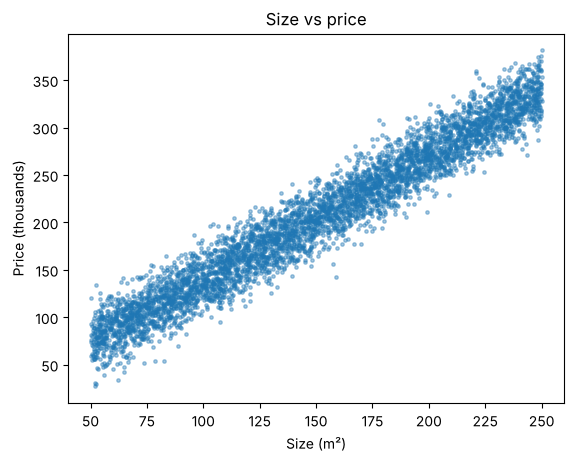

In [ ]:
plt.scatter(df["size_m2"], df["price_thousands"], s=6, alpha=0.4)
plt.xlabel("Size (m²)")
plt.ylabel("Price (thousands)")
plt.title("Size vs price")
plt.show()

## 4. Split into training and test sets

We train on 70% of the houses and test on the other 30%, so we can see how the model does on houses it has **never seen**.

In [ ]:
x = df["size_m2"].to_numpy()
y = df["price_thousands"].to_numpy()

rng = np.random.default_rng(0)
idx = rng.permutation(len(y))
cut = int(0.7 * len(y))
train, test = idx[:cut], idx[cut:]

x_train, y_train = x[train], y[train]
x_test, y_test = x[test], y[test]
print("Training rows:", len(train), "  Test rows:", len(test))

Training rows: 3500   Test rows: 1500


## 5. Train the model

The least-squares formulas for one input are:

$$w = \frac{\sum (x-\bar{x})(y-\bar{y})}{\sum (x-\bar{x})^2} \qquad b = \bar{y} - w\,\bar{x}$$

In [ ]:
w = np.sum((x_train - x_train.mean()) * (y_train - y_train.mean())) / np.sum((x_train - x_train.mean()) ** 2)
b = y_train.mean() - w * x_train.mean()

print(f"price = {b:.2f} + {w:.3f} * size")
print(f"Each extra square metre adds about {w:.3f} thousand to the price.")

price = 7.17 + 1.322 * size
Each extra square metre adds about 1.322 thousand to the price.


## 6. Predict on the test set

In [ ]:
pred = b + w * x_test

## 7. Evaluate

| Metric | Meaning |
|---|---|
| **MAE** | average size of the error, in price units |
| **MSE** | average of the squared errors (big misses are punished more) |
| **RMSE** | square root of MSE, back in price units |
| **R²** | share of the variation in price the model explains (1 = perfect, 0 = no better than the average) |

In [ ]:
residuals = y_test - pred
mae = np.mean(np.abs(residuals))
mse = np.mean(residuals ** 2)
rmse = np.sqrt(mse)
r2 = 1 - np.sum(residuals ** 2) / np.sum((y_test - y_test.mean()) ** 2)

print(f"MAE  = {mae:.2f}")
print(f"MSE  = {mse:.2f}")
print(f"RMSE = {rmse:.2f}")
print(f"R2   = {r2:.3f}")

MAE  = 14.22
MSE  = 321.25
RMSE = 17.92
R2   = 0.946


## 8. Plots

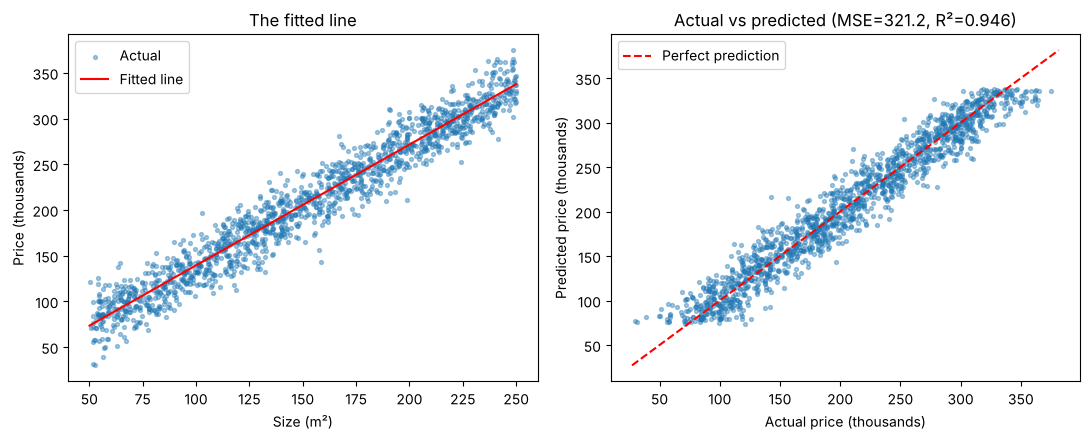

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: the fitted line over the test data
axes[0].scatter(x_test, y_test, s=8, alpha=0.4, label="Actual")
line_x = np.linspace(x.min(), x.max(), 100)
axes[0].plot(line_x, b + w * line_x, "r", label="Fitted line")
axes[0].set_xlabel("Size (m²)")
axes[0].set_ylabel("Price (thousands)")
axes[0].set_title("The fitted line")
axes[0].legend()

# Right: actual vs predicted
axes[1].scatter(y_test, pred, s=8, alpha=0.4)
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Perfect prediction")
axes[1].set_xlabel("Actual price (thousands)")
axes[1].set_ylabel("Predicted price (thousands)")
axes[1].set_title(f"Actual vs predicted (MSE={mse:.1f}, R²={r2:.3f})")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Conclusion

- The model explains about **94.6%** of the variation in price using size alone (R² ≈ 0.946).
- Typical error is about **18 thousand** (RMSE).
- Dots on the actual-vs-predicted plot close to the red dashed line are accurate predictions.
- Size is not the only thing that affects price, so adding more inputs should improve the model. That is the next notebook (**multiple linear regression**).